# 基础数字 SRAM-CIM 宏与数据搬移教程

本教程使用 `basic_digital_sram_512x8_with_movement`。该宏包含 512 个归约输入、8 个逻辑输出列、8b 权重、1b 串行输入、512 输入 Adder Tree 和 25b 累加器。ADC 与 DAC 不参与该模型，同时加入了 GlobalBuffer、MainMemory 以及行列驱动器的初步能耗估计。

In [1]:
from _scripts import get_spec
from basic_digital_sram_512x8_macro_model import evaluate_mappings_with_peripherals
import accelforge as af
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

## 宏结构

一个逻辑 `512 x 8` VMM tile 使用 `512 x 64` 个物理 SRAM bitcell：每个逻辑输出列有 8 条 weight-bit 列，用于存储 8b 权重。每个时钟周期向 512 行同时送入一个 activation bit；处理完整 8b activation 需要 8 个周期。

每个逻辑输出列先将 512 个 `1b x 8b` 部分积经 Adder Tree 归约为 17b，再由 25b 累加器完成移位累加。

,数值
物理 bitcell 阵列,512 x 64
逻辑计算 tile,512 x 8
输入位周期数,8
Adder Tree 输出位宽,17
累加器位宽,25
CSV 能效 (TOPS/W),17.03
CSV 面积效率 (TOPS/mm^2),2.24
宏面积 (mm^2),0.228571


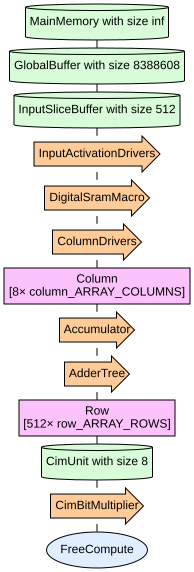

In [2]:
cost_spec = get_spec("basic_digital_sram_512x8_with_movement").calculate_component_costs(
    einsum_name="Matmul"
)
variables = cost_spec.arch.variables
macro_area_mm2 = cost_spec.arch.find("DigitalSramMacro").total_area * 1e6

summary = {
    "物理 bitcell 阵列": f"{variables.array_wordlines} x {variables.array_bitlines}",
    "逻辑计算 tile": f"{variables.logical_array_rows} x {variables.logical_array_columns}",
    "输入位周期数": variables.macro_bit_cycles_per_full_vmm,
    "Adder Tree 输出位宽": variables.partial_sum_bits,
    "累加器位宽": variables.accumulator_bits,
    "CSV 能效 (TOPS/W)": variables.characterized_energy_efficiency_tops_per_w,
    "CSV 面积效率 (TOPS/mm^2)": variables.characterized_area_efficiency_tops_per_mm2,
    "宏面积 (mm^2)": macro_area_mm2,
}
display(pd.Series(summary, name="数值").to_frame())
cost_spec.arch

## 满载基准 VMM

默认 workload 为 `M=1, K=512, N=8`，恰好填满一个逻辑宏 tile。能耗与面积由 `docs/source/cim_macro_efficiency.csv` 中 `AL=512, PC=8, WB=8, IB=8` 的效率数据校准。

总能耗: 262.2558 nJ
其中 CIM macro: 0.4810 nJ
其中外围与数据搬移: 261.7747 nJ
总延迟: 128.00 ns
物理宏调用数: 1


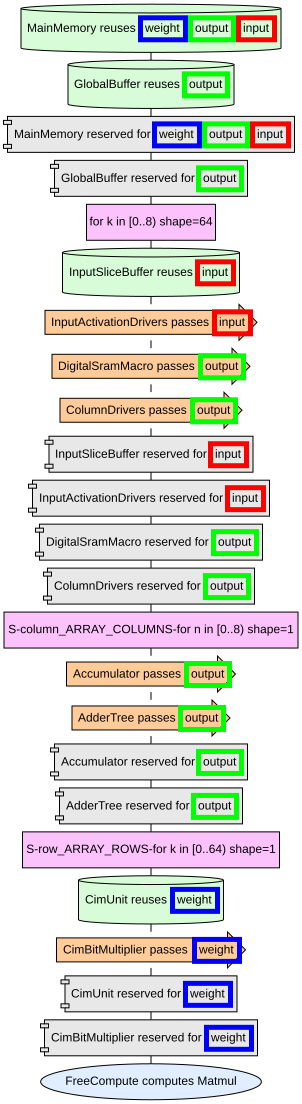

In [3]:
spec = get_spec("basic_digital_sram_512x8_with_movement")
spec.mapper.metrics = af.Metrics.ENERGY
result = spec.map_workload_to_arch(print_progress=False)
combined = evaluate_mappings_with_peripherals(result)[0]
print(f"总能耗: {combined['energy_j'] * 1e9:.4f} nJ")
print(f"其中 CIM macro: {combined['macro_energy_j'] * 1e9:.4f} nJ")
print(f"其中外围与数据搬移: {combined['peripheral_energy_j'] * 1e9:.4f} nJ")
print(f"总延迟: {combined['latency_s'] * 1e9:.2f} ns")
print(f"物理宏调用数: {combined['macro_invocations']:,}")
result

上面的 mapping 应显示 `n` 被映射到 8 个 `Column` 实例，`k` 被映射到 512 个 `Row` 实例。`DigitalSramMacro` 的 8 次动作对应 8 个 activation bit 周期。

能耗分为两部分：`DigitalSramMacro` 使用 CSV 标定的物理宏能耗，`MainMemory`、`GlobalBuffer`、行驱动器和列驱动器由 AccelForge 统计。这样可以观察数据搬移相对 CIM 计算的影响，同时避免重复计算宏内部的通用乘法器、Adder Tree 与累加器模型。

## 基于 CSV 的设计空间探索

效率表覆盖 `AL = [32, 64, 128, 256, 512]` 和 `PC = [8, 16, 32, 64]`。下面仅评估表中已有的组合；若请求表外配置，模型会报错而不会擅自插值。

In [4]:
AL_CHOICES = [32, 64, 128, 256, 512]
PC_CHOICES = [8, 16, 32, 64]


def configured_spec(al, pc):
    spec = get_spec("basic_digital_sram_512x8_with_movement")
    spec.arch.variables.logical_array_rows = al
    spec.arch.variables.logical_array_columns = pc
    spec.workload.rank_sizes["K"] = al
    spec.workload.rank_sizes["N"] = pc
    return spec


def evaluate_characterized_macro(al, pc):
    spec = configured_spec(al, pc)
    spec.mapper.metrics = af.Metrics.ENERGY
    mapped = spec.map_workload_to_arch(print_progress=False)
    physical = evaluate_mappings_with_peripherals(mapped)[0]
    variables = mapped.evaluated_specs["Matmul"].arch.variables
    area_spec = configured_spec(al, pc)
    area_spec = area_spec.calculate_component_costs(einsum_name="Matmul")
    area_mm2 = area_spec.arch.find("DigitalSramMacro").total_area * 1e6
    return {
        "AL": al,
        "PC": pc,
        "energy_nJ": physical["energy_j"] * 1e9,
        "macro_energy_nJ": physical["macro_energy_j"] * 1e9,
        "peripheral_energy_nJ": physical["peripheral_energy_j"] * 1e9,
        "latency_ns": physical["latency_s"] * 1e9,
        "area_mm2": area_mm2,
        "macro_TOPS_per_W": variables.characterized_energy_efficiency_tops_per_w,
        "TOPS_per_W": physical["TOPS_per_W"],
        "TOPS_per_mm2": variables.characterized_area_efficiency_tops_per_mm2,
    }


sweep = pd.DataFrame(
    evaluate_characterized_macro(al, pc)
    for al in AL_CHOICES
    for pc in PC_CHOICES
)
sweep.sort_values(["AL", "PC"])

,AL,PC,energy_nJ,macro_energy_nJ,peripheral_energy_nJ,latency_ns,area_mm2,macro_TOPS_per_W,TOPS_per_W,TOPS_per_mm2
0,32,8,18.902131,0.084211,18.81792,127.999996,0.014350,6.08,0.027087,2.23
1,32,16,35.982655,0.146495,35.83616,127.999996,0.026230,6.99,0.028458,2.44
2,32,32,70.152422,0.279781,69.87264,127.999996,0.045230,7.32,0.029194,2.83
3,32,64,138.443897,0.498297,137.94560,127.999996,0.087075,8.22,0.029586,2.94
4,64,8,35.148721,0.133681,35.01504,127.999996,0.029091,7.66,0.029133,2.20
5,64,16,66.662132,0.231412,66.43072,127.999996,0.055652,8.85,0.030722,2.30
6,64,32,129.750863,0.488783,129.26208,127.999996,0.096970,8.38,0.031568,2.64
7,64,64,255.730307,0.805506,254.92480,127.999996,0.180282,10.17,0.032034,2.84
8,128,8,67.590840,0.181560,67.40928,127.999996,0.055411,11.28,0.030300,2.31
9,128,16,127.975396,0.355556,127.61984,127.999996,0.108017,11.52,0.032006,2.37


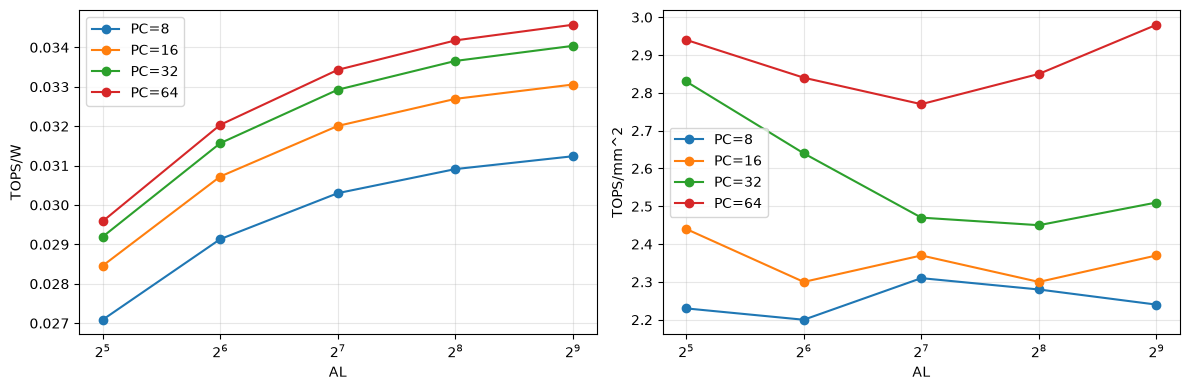

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for pc, group in sweep.groupby("PC"):
    axes[0].plot(group["AL"], group["TOPS_per_W"], marker="o", label=f"PC={pc}")
    axes[1].plot(group["AL"], group["TOPS_per_mm2"], marker="o", label=f"PC={pc}")

for ax, ylabel in zip(axes, ["TOPS/W", "TOPS/mm^2"]):
    ax.set_xlabel("AL")
    ax.set_ylabel(ylabel)
    ax.set_xscale("log", base=2)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

## ResNet-18 能效评估

下面导入 `af.examples.workloads.compute_in_memory.resnet18`，并以 `BATCH_SIZE=1` 映射到一个数字 SRAM-CIM macro。该 workload 包含卷积和全连接的 einsum；它不包含 ReLU、BatchNorm、池化和残差逐元素加法，因此结果表示这些矩阵/卷积计算的宏级评估，而非完整网络的软件端到端能耗。

In [6]:
workload_path = af.examples.workloads.compute_in_memory.resnet18
resnet_spec = get_spec("basic_digital_sram_512x8_with_movement")
resnet_spec.workload = af.Workload.from_yaml(
    workload_path,
    top_key="workload",
    jinja_parse_data={"BATCH_SIZE": 1},
)
resnet_spec.renames = af.Renames.from_yaml(
    workload_path,
    top_key="renames",
    jinja_parse_data={"BATCH_SIZE": 1},
)
resnet_spec.mapper.metrics = af.Metrics.ENERGY

resnet_result = resnet_spec.map_workload_to_arch(print_progress=False)
resnet_physical_results = evaluate_mappings_with_peripherals(resnet_result)
print(f"Einsum 数量: {len(resnet_physical_results)}")
print(f"总能耗: {sum(item['energy_j'] for item in resnet_physical_results) * 1e3:.4f} mJ")
print(f"总延迟: {sum(item['latency_s'] for item in resnet_physical_results) * 1e3:.4f} ms")

Einsum 数量: 21
总能耗: 5.6881 mJ
总延迟: 57.8188 ms


In [7]:
layer_results = pd.DataFrame(resnet_physical_results)
layer_results["energy_uJ"] = layer_results["energy_j"] * 1e6
layer_results["latency_us"] = layer_results["latency_s"] * 1e6
layer_results = layer_results.sort_values("energy_uJ", ascending=False)
layer_results[[
    "layer", "MACs", "K", "N", "output_positions",
    "macro_invocations", "macro_cycles", "macro_energy_j",
    "peripheral_energy_j", "energy_uJ",
    "latency_us", "TOPS", "TOPS_per_W",
]]

,layer,MACs,K,N,output_positions,macro_invocations,macro_cycles,macro_energy_j,peripheral_energy_j,energy_uJ,latency_us,TOPS,TOPS_per_W
18,T18,115605504,4608,512,49,28224,225792,1.357669e-05,0.000416,429.399095,3612.671979,0.064,0.538452
19,T19,115605504,4608,512,49,28224,225792,1.357669e-05,0.000416,429.399095,3612.671979,0.064,0.538452
16,T16,115605504,4608,512,49,28224,225792,1.357669e-05,0.000416,429.399095,3612.671979,0.064,0.538452
0,T0,118013952,147,64,12544,100352,802816,4.827267e-05,0.000361,409.331033,4816.895816,0.049,0.576619
11,T11,115605504,2304,256,196,31360,250880,1.508521e-05,0.000320,334.611148,3612.671979,0.064,0.690984
13,T13,115605504,2304,256,196,31360,250880,1.508521e-05,0.000320,334.611148,3612.671979,0.064,0.690984
14,T14,115605504,2304,256,196,31360,250880,1.508521e-05,0.000320,334.611148,3612.671979,0.064,0.690984
2,T2,115605504,576,64,3136,50176,401408,2.413634e-05,0.000308,332.279466,3612.671979,0.064,0.695833
1,T1,115605504,576,64,3136,50176,401408,2.413634e-05,0.000308,332.279466,3612.671979,0.064,0.695833
4,T4,115605504,576,64,3136,50176,401408,2.413634e-05,0.000308,332.279466,3612.671979,0.064,0.695833


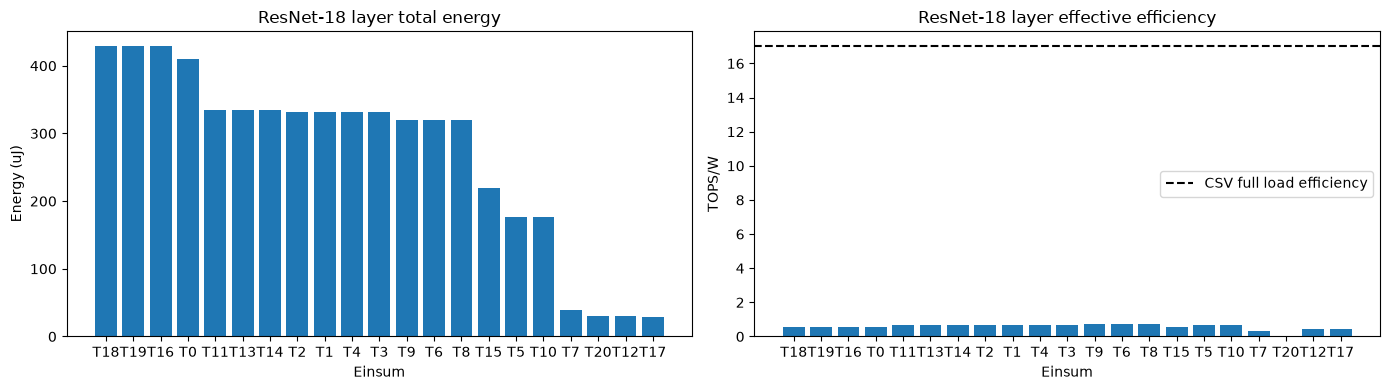

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(layer_results["layer"], layer_results["energy_uJ"])
axes[0].set_xlabel("Einsum")
axes[0].set_ylabel("Energy (uJ)")
axes[0].set_title("ResNet-18 layer total energy")

axes[1].bar(layer_results["layer"], layer_results["TOPS_per_W"])
axes[1].axhline(17.03, color="black", linestyle="--", label="CSV full load efficiency")
axes[1].set_xlabel("Einsum")
axes[1].set_ylabel("TOPS/W")
axes[1].set_title("ResNet-18 layer effective efficiency")
axes[1].legend()

plt.tight_layout()

满载层的有效能效应接近 CSV 的 `17.03 TOPS/W`。当卷积层的归约维度不能填满 512 行时，宏仍以完整 bit-serial 周期工作，单位 MAC 的有效能效会下降。

下一步可根据每层的 `K`、`N` 与实际使用的宏数量，研究多 macro 并行、列/行 power gating，以及不同 AL/PC 组合对 ResNet-18 的影响。